# Give Me Some Credit

## Problema, objetivo y procedencia de los datos

Este proyecto aborda una clasificación binaria con datos tabulares: predecir si una persona experimentará morosidad de 90 días o más en un horizonte de dos años. La variable objetivo es `SeriousDlqin2yrs`: 1 representa el evento y 0 su ausencia. Se utilizan los archivos `cs-training.csv`, `cs-test.csv` y `Data Dictionary.xls`, descargados de la competencia **Give Me Some Credit de Kaggle** [1].

Elegí este dataset porque contiene una respuesta binaria y diez predictores numéricos de ingresos, endeudamiento e historial crediticio. Permite estudiar datos faltantes, asimetría, clases desbalanceadas y el compromiso entre detectar morosidad y generar falsas alarmas. El propósito es comparar dos enfoques clásicos para datos tabulares, regresión logística y XGBoosting, y justificar sus decisiones de evaluación.

Se distingue el conjunto de test de Kaggle, cuyas etiquetas no están disponibles, del **test interno reservado** a partir del archivo etiquetado. Los valores y resultados descritos a continuación proceden de nuestros archivos; las referencias respaldan los métodos, no garantizan que una decisión concreta sea óptima para este dataset.

### Configuración y reproducibilidad

Se importan las bibliotecas, se fija la semilla 42 y se localizan los archivos. La semilla permite reproducir las particiones y los pasos aleatorios configurados; no convierte las observaciones en independientes.

In [6]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

SEED = 42
TARGET = "SeriousDlqin2yrs"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cs-training.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Abre este notebook desde la carpeta GiveMeSomeCredit.")
print("Proyecto:", ROOT)


Proyecto: /Users/lenytacuri/GiveMeSomeCredit


### Lectura y diccionario

Se cargan los dos CSV y se presenta el diccionario original. `index_col=0` mantiene el identificador fuera de los predictores. `cs-test.csv` se inspecciona como archivo de Kaggle, pero no se usa para calcular métricas sin sus etiquetas [1].

In [ ]:
if ROOT is None:
    raise FileNotFoundError(
        "No se encontró la carpeta que contiene cs-training.csv."
    )

train = pd.read_csv(ROOT / "cs-training.csv", index_col=0)
test = pd.read_csv(ROOT / "cs-test.csv", index_col=0)
dictionary = pd.read_excel(ROOT / "Data Dictionary.xls", header=1)
print("Entrenamiento:", train.shape)
print("Prueba:", test.shape)
display(dictionary)
display(train.head())


Entrenamiento: (150000, 11)
Prueba: (101503, 11)


,Variable Name,Description,Type
0,SeriousDlqin2yrs,Person experienced 90 days past due delinquenc...,Y/N
1,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lin...,percentage
2,age,Age of borrower in years,integer
3,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days p...,integer
4,DebtRatio,"Monthly debt payments, alimony,living costs di...",percentage
5,MonthlyIncome,Monthly income,real
6,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loa...,integer
7,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or m...,integer
8,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans inclu...,integer
9,NumberOfTime60-89DaysPastDueNotWorse,Number of times borrower has been 60-89 days p...,integer


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## Calidad de los datos

El identificador de la primera columna se conserva como índice para rastrear observaciones; no entra en las variables predictoras. El diccionario permite distinguir los conteos de morosidad de la razón de utilización del crédito: `RevolvingUtilizationOfUnsecuredLines` relaciona el saldo de tarjetas y líneas personales con sus límites [1].

Se revisan tipos, faltantes, extremos y disponibilidad de etiquetas. Los valores extraordinarios requieren investigación: su magnitud, por sí sola, no demuestra que sean errores.

El siguiente bloque resume tipos, faltantes y rangos; comprueba la unicidad de los identificadores y la ausencia de etiquetas utilizables en el test de Kaggle. 

In [43]:
display(train.dtypes.to_frame("tipo"))
display(train.isna().sum().sort_values(ascending=False).to_frame("faltantes en archivo train"))
display(train.describe().T)
print("Identificadores únicos en conjunto de entrenamiento:", train.index.is_unique)
print("Etiquetas disponibles en conjunto de prueba:", test[TARGET].notna().sum() if TARGET in test else 0)


,tipo
SeriousDlqin2yrs,int64
RevolvingUtilizationOfUnsecuredLines,float64
age,int64
NumberOfTime30-59DaysPastDueNotWorse,int64
DebtRatio,float64
MonthlyIncome,float64
NumberOfOpenCreditLinesAndLoans,int64
NumberOfTimes90DaysLate,int64
NumberRealEstateLoansOrLines,int64
NumberOfTime60-89DaysPastDueNotWorse,int64


,faltantes en archivo train
MonthlyIncome,29731
NumberOfDependents,3924
SeriousDlqin2yrs,0
RevolvingUtilizationOfUnsecuredLines,0
age,0
NumberOfTime30-59DaysPastDueNotWorse,0
DebtRatio,0
NumberOfOpenCreditLinesAndLoans,0
NumberOfTimes90DaysLate,0
NumberRealEstateLoansOrLines,0


,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


Identificadores únicos en conjunto de entrenamiento: True
Etiquetas disponibles en conjunto de prueba: 0


Se cuentan y grafican las clases del archivo etiquetado original. Esta distribución sirve como descripción de la fuente; las métricas de selección se calcularán posteriormente dentro de los folds de entrenamiento.

,cantidad,proporción
SeriousDlqin2yrs,,
0,139974,0.93316
1,10026,0.06684


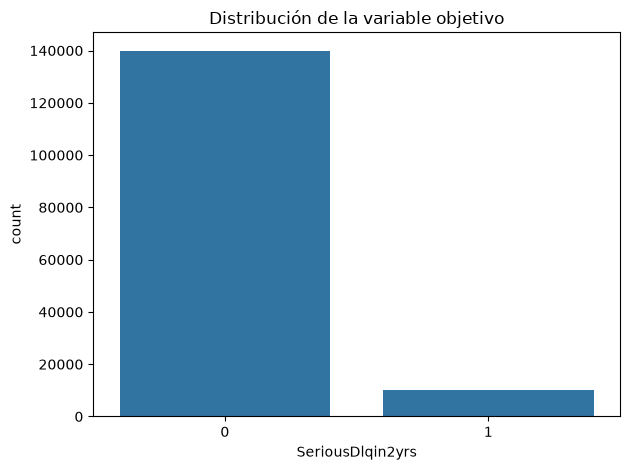

In [ ]:
display(train[TARGET].value_counts().rename("cantidad").to_frame().join(train[TARGET].value_counts(normalize=True).rename("proporción")))
sns.countplot(data=train, x=TARGET)
plt.title("Distribución de la variable objetivo")
plt.tight_layout()
plt.show()

## Preparación de los datos y separación de entrenamiento y test

`cs-training.csv` contiene 150 000 observaciones etiquetadas. Se eliminan las 29 731 filas sin `MonthlyIncome` (19.82%). En estos archivos, las 3 924 filas sin `NumberOfDependents` están incluidas en ese conjunto; después del filtro no quedan faltantes. Quedan **120 269 filas**, que se dividen en **96 215 para entrenamiento (80%)** y **24 054 para test (20%)**, conservando aproximadamente la proporción de clases mediante estratificación [2].

La eliminación se adoptó por simplicidad y porque conservamos una muestra considerable. No se demostró que la ausencia de ingresos sea completamente aleatoria: eliminar casos puede cambiar la población y sesgar resultados; la imputación sería una alternativa que requiere supuestos y evaluación [3]. Por ello, las conclusiones se refieren a personas con ingresos observados, y no necesariamente a las filas excluidas.

El filtro por ausencia se aplica antes del split sin estimar parámetros ni usar la etiqueta. Después, las transformaciones aprendidas y la selección se ajustan dentro de cada entrenamiento de CV. El test interno queda reservado para la evaluación final [4].

Se filtran las filas sin ingresos, se separan los predictores de la respuesta y se realiza el split estratificado 80/20 con semilla 42. Los identificadores se conservan para auditar la correspondencia entre modelos.

In [10]:
from sklearn.model_selection import train_test_split

df = train.copy()

df = df.dropna(subset=["MonthlyIncome"])

X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


X_train: (96215, 10)
y_train: (96215,)
X_test: (24054, 10)
y_test: (24054,)


## Selección de variables y relaciones entre predictores

Se utilizaron filtros univariados dentro de los pipelines: ANOVA F para regresión logística e información mutua para XGBoost. Puntúan cada predictor respecto a la etiqueta; no son métodos de balanceo de clases ni garantizan detectar interacciones. La regularización del modelo es un mecanismo diferente [5].

La correlación de Pearson se explora en `X_train` como diagnóstico de asociación lineal. Es simétrica y adimensional, mientras que la covarianza conserva el producto de las unidades originales. Este cuaderno grafica la **correlación**, no usa un umbral de correlación para eliminar variables.

Las variables de atraso representan frecuencias en intervalos diferentes según el diccionario; no se supone que el conteo de 90 días incluya automáticamente los de 30–59 y 60–89 días. Una correlación elevada puede estar influida por valores extremos compartidos. Sin evidencia adicional, no se eliminan como si fueran duplicados [1].

Se calcula y dibuja la correlación de Pearson exclusivamente con `X_train`. El mapa se interpreta como diagnóstico exploratorio; no selecciona automáticamente variables ni utiliza `y_test`.

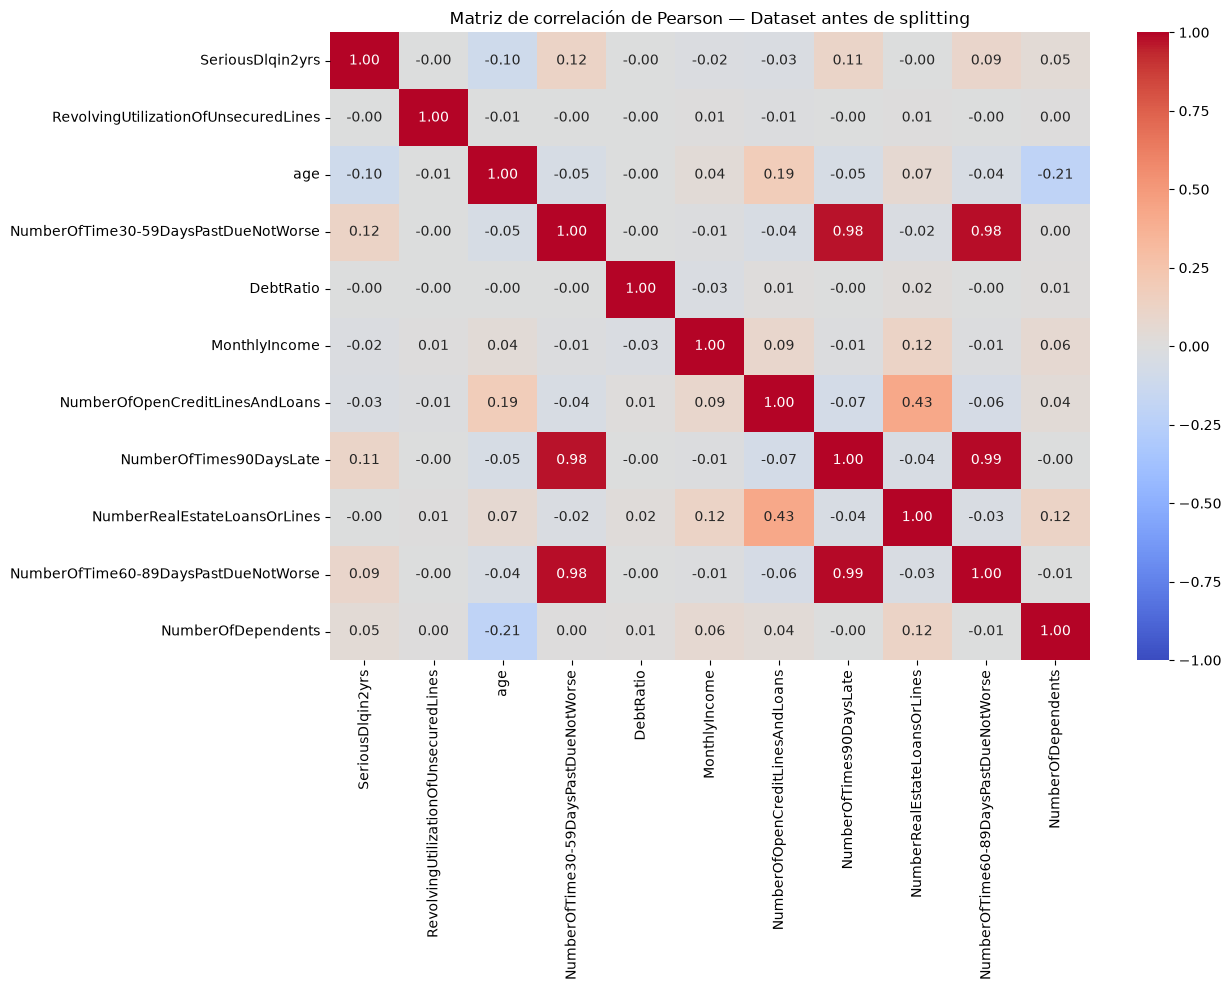

In [45]:
corr_matrix = df.corr(method="pearson")

plt.figure(figsize=(13, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlación de Pearson — Dataset antes de splitting")
plt.tight_layout()
plt.show()


## Distribución y asimetría

Se inspeccionan histogramas y asimetría en el entrenamiento. Los gráficos conservan el rango completo: una barra muy concentrada puede deberse a una cola larga, y no a falta de variación. La asimetría elevada motiva evaluar transformaciones, pero no implica que todos los modelos requieran predictores normales.

Se dibuja un histograma por predictor y se muestra su coeficiente de asimetría. Se conservan 40 bins y el rango observado completo para visualizar también el efecto de las colas.

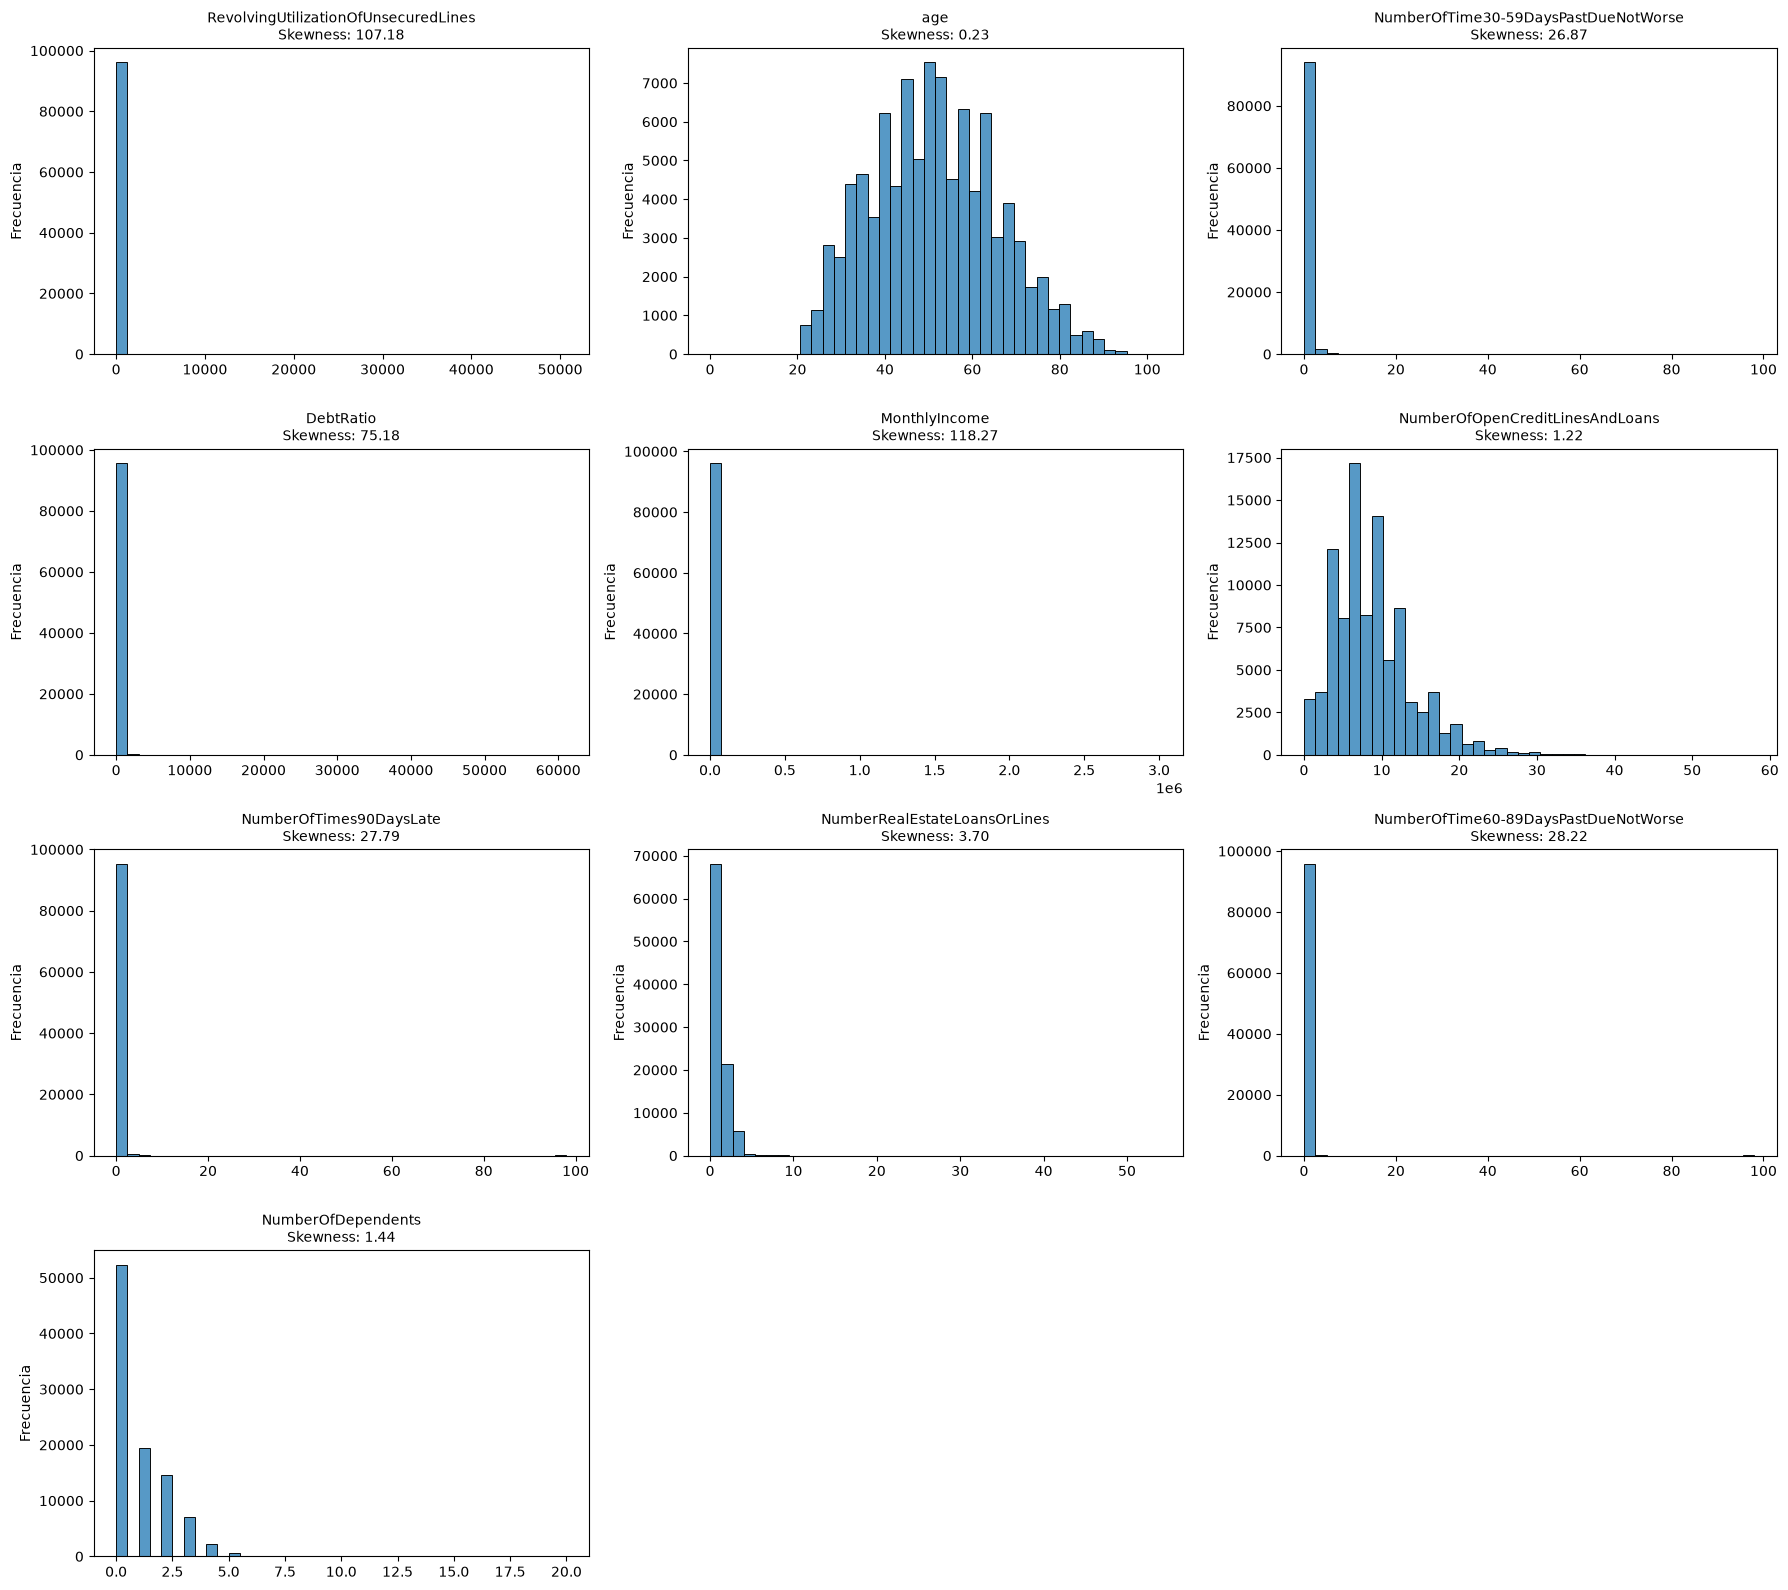

In [12]:
skewness = X_train.skew()

n_cols = 3
n_rows = (len(X_train.columns) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4 * n_rows)
)

axes = axes.flatten()

for ax, feature in zip(axes, X_train.columns):
    sns.histplot(
        data=X_train,
        x=feature,
        bins=40,
        ax=ax
    )

    ax.set_title(
        f"{feature}\nSkewness: {skewness[feature]:.2f}",
        fontsize=10
    )
    ax.set_xlabel("")
    ax.set_ylabel("Frecuencia")

for ax in axes[len(X_train.columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


## Estadísticos y valores extremos

Los máximos de `RevolvingUtilizationOfUnsecuredLines` y de las tres variables de morosidad llamaron especialmente la atención. El bloque siguiente muestra estadísticos, incluidos mínimos y máximos; no realiza una eliminación de outliers.

Los conteos extraordinarios, como 96 o 98, podrían corresponder a convenciones de registro, pero el diccionario disponible no confirma ese significado. Conservamos sus valores y documentamos esta incertidumbre. El logaritmo puede comprimir su magnitud, pero no corregir un eventual error semántico.

Se muestran los estadísticos descriptivos del entrenamiento después de filtrar faltantes, para contrastar los histogramas con los valores numéricos de cada variable.

In [ ]:
display(X_train.describe().T)

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,96215.0,6.020631,258.550660,0.0,0.035507,0.179148,0.581634,50708.0
age,96215.0,51.304464,14.404538,0.0,41.000000,51.000000,61.000000,103.0
NumberOfTime30-59DaysPastDueNotWorse,96215.0,0.378558,3.478053,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,96215.0,26.836417,447.741573,0.0,0.143736,0.296494,0.483735,61106.5
MonthlyIncome,96215.0,6677.168934,14782.576908,0.0,3400.000000,5400.000000,8231.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,96215.0,8.772593,5.180850,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,96215.0,0.210456,3.444836,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,96215.0,1.056363,1.151067,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,96215.0,0.186218,3.427097,0.0,0.000000,0.000000,0.000000,98.0
NumberOfDependents,96215.0,0.854503,1.152136,0.0,0.000000,0.000000,2.000000,20.0


## Desbalance de clases

En `y_train` hay **89 529 negativos y 6 686 positivos**: aproximadamente 6.95% pertenece a la clase de interés. Predecir siempre 0 daría cerca de 93.05% de accuracy y recall positivo cero. Esta cuenta propia muestra por qué accuracy no será la métrica de selección; se conserva como información complementaria [6].

El balanceo no es obligatorio por el solo hecho de existir desbalance. En regresión logística se comparan ausencia de submuestreo y tres intensidades de `RandomUnderSampler`, aplicadas únicamente durante el ajuste del pipeline. Sus ratios son positivos/negativos **después** de muestrear: 0.25, 0.5 y 1 corresponden a 1:4, 1:2 y 1:1 [7]. La validación y el test mantienen su distribución original. XGBoost usa ponderación de la clase positiva en lugar de descartar filas.

Se cuentan las clases de `y_train` antes de cualquier submuestreo. Esta es la distribución que conservan aproximadamente las validaciones estratificadas.

In [ ]:
print (y_train.value_counts().sort_index())

SeriousDlqin2yrs
0    89529
1     6686
Name: count, dtype: int64


## Primera técnica: regresión logística

Elegí regresión logística como baseline clásico de clasificación binaria: es un modelo parsimonioso que permite estudiar efectos aditivos sobre el logaritmo de las odds. Se ajusta al objetivo de producir un score para dos clases y ofrece una referencia frente a un modelo no lineal. No se supone que los predictores deban ser normales [8].

El pipeline aplica `log1p` a todos los predictores salvo `age`, estandariza, selecciona variables mediante `SelectKBest(f_classif)`, realiza el submuestreo elegido y ajusta la regresión. El logaritmo comprime las colas y admite ceros; se deja edad en su escala inicial por su distribución menos asimétrica. La estandarización hace comparables las escalas para la regularización, aprendiendo media y desviación únicamente con las filas de ajuste [9]. `f_classif` funciona aquí como criterio de ordenación, no como una prueba inferencial definitiva sobre predictores con distribuciones no normales [5].

### Métrica principal: por qué F1 positivo y no solamente ROC-AUC

Mi objetivo es detectar casos de morosidad sin convertir una mejora de recall en un exceso de falsas alarmas. Por eso selecciono por **F1 de la clase 1**, que exige un compromiso entre precisión y recall:

$$P=\frac{TP}{TP+FP},\qquad R=\frac{TP}{TP+FN},\qquad F1=\frac{2PR}{P+R}=\frac{2TP}{2TP+FP+FN}.$$

Una precisión alta con recall muy bajo no es suficiente, y tampoco lo es detectar casi todos los positivos a costa de señalar a demasiados negativos. F1 resume ambos aspectos en un umbral concreto y no incorpora los verdaderos negativos a su fórmula [6].

ROC-AUC evalúa la capacidad de ordenar positivos por encima de negativos a través de diferentes umbrales. Continúa siendo válida con desbalance, pero un buen AUC no garantiza alta precisión en el punto de operación: una tasa pequeña de falsos positivos puede representar muchas alertas cuando abundan los negativos. La literatura respalda examinar también precision-recall en este contexto, sin establecer que F1 sea universalmente superior a ROC-AUC [10].

Por tanto, **la elección de F1 responde al objetivo del proyecto**, no a una regla automática por desbalance. No garantiza un máximo de falsos positivos, una precisión mínima ni costos económicos iguales. Si se exigiera alguna de esas restricciones, habría que definirla antes de seleccionar el modelo. Reportamos las cinco métricas y la curva precision-recall para evitar ocultar el compromiso detrás de un único número.

En ambos GridSearch, `refit="f1"` selecciona por el F1 medio de validación a umbral 0.5. ROC-AUC, accuracy, precisión y recall se guardan, pero no deciden la combinación ganadora. La optimización numérica de cada algoritmo sigue usando su pérdida de clasificación; no se entrena directamente minimizando F1.

### Pipeline de regresión logística

Se construye el pipeline completo. `log1p` es una transformación fija; el escalador, el filtro y el modelo se ajustan de nuevo dentro de cada fold. El sampler solo actúa durante el entrenamiento. Esta organización reduce la fuga de información desde la validación [4].

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

log_transform = ColumnTransformer(
    [("log", FunctionTransformer(np.log1p), X_train.columns.drop("age").tolist())],
    remainder="passthrough",
)
pipeline_lr = Pipeline([
    ("log", log_transform),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(f_classif)),
    ("sampler", RandomUnderSampler(random_state=SEED)),
    ("model", LogisticRegression(solver="lbfgs", max_iter=2000)),
])


### Espacio de búsqueda y validación

Se definen las cinco métricas, siempre con la clase 1 como positiva para precisión, recall y F1. La CV es `RepeatedStratifiedKFold(10, 10, random_state=42)`.

La búsqueda compara **C = [0.01, 0.1, 1, 10, 100]** en escala logarítmica para cubrir regularización fuerte y débil: menor C implica mayor penalización. Se utiliza la regularización L2 de la configuración de regresión logística. El parámetro **k = [5, 7, 9, "all"]** compara distintos tamaños de selección, y se prueban cuatro alternativas de submuestreo, incluida su ausencia [8], [7]. Los valores concretos son decisiones experimentales del proyecto, no rangos universalmente óptimos recomendados por una fuente.

In [16]:
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold

scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
}
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=SEED)
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "selector__k": [5, 7, 9, "all"],
    "sampler": ["passthrough"] + [
        RandomUnderSampler(sampling_strategy=ratio, random_state=SEED)
        for ratio in [0.25, 0.5, 1.0]
    ],
}
RESULTS_DIR = ROOT / "results" / "regresion_logistica" / "log_f1"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


### Búsqueda de hiperparámetros

Las 5 opciones de C × 4 de k × 4 de muestreo generan **80 combinaciones y 8 000 ajustes de CV**, más el reajuste final de la ganadora sobre todo `X_train`. El mayor F1 medio determina la selección. `return_train_score=True` guarda scores de entrenamiento para diagnóstico, pero no predicciones individuales [11].

In [17]:
search_lr = GridSearchCV(
    pipeline_lr, param_grid, scoring=scoring, refit="f1", cv=cv,
    return_train_score=True, n_jobs=-1, error_score="raise",
)
search_lr.fit(X_train, y_train);


### Resultados de selección y persistencia

Se guardan el GridSearch, sus scores por fold, la configuración ganadora y el orden de las filas. Se muestran únicamente los hiperparámetros elegidos y las cinco métricas medias de validación. En estos archivos, `test` significa la validación de cada fold, no `X_test`. Son resultados usados para seleccionar, no una evaluación externa independiente.

In [20]:
import json
import joblib

results_lr = pd.DataFrame(search_lr.cv_results_)
results_lr.to_csv(RESULTS_DIR / "gridsearch.csv", index=False)
joblib.dump(search_lr, RESULTS_DIR / "gridsearch.joblib", compress=3)
X_train.index.to_series().to_csv(RESULTS_DIR / "orden_train.csv", index=False)

sampler = search_lr.best_params_["sampler"]
selected_params = {
    "C": search_lr.best_params_["model__C"],
    "k": search_lr.best_params_["selector__k"],
    "positivos_por_negativo": None if sampler == "passthrough" else sampler.sampling_strategy,
}
(RESULTS_DIR / "hiperparametros.json").write_text(
    json.dumps(selected_params, indent=2), encoding="utf-8"
)
print(f"C: {selected_params['C']}; variables: {selected_params['k']}")
print("Submuestreo (positivos/negativos):", selected_params["positivos_por_negativo"] or "sin submuestreo")

best = results_lr.iloc[search_lr.best_index_]
summary_lr = pd.DataFrame({
    "validacion_media": [best[f"mean_test_{m}"] for m in scoring],
    "validacion_std": [best[f"std_test_{m}"] for m in scoring],
}, index=list(scoring))
summary_lr.to_csv(RESULTS_DIR / "resumen_validacion.csv")
print("Validación del GridSearch (umbral 0.5):")
print(summary_lr.round(4).to_string())


C: 0.01; variables: 5
Submuestreo (positivos/negativos): 0.5
Validación del GridSearch (umbral 0.5):
           validacion_media  validacion_std
roc_auc              0.8426          0.0077
accuracy             0.8989          0.0033
precision            0.3497          0.0125
recall               0.5285          0.0191
f1                   0.4208          0.0132


### Probabilidades de validación

Con los hiperparámetros ganadores fijos, se realizan 100 ajustes adicionales y se guarda una probabilidad por observación de validación, junto con su identificador y split. Cada persona recibe diez predicciones, una por repetición. El pipeline que la predice no se ajustó con ella en ese fold, aunque la selección previa de hiperparámetros sí utilizó el conjunto de desarrollo.

In [18]:
from sklearn.base import clone

predicciones_lr = []

for split, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train)):
    modelo_fold = clone(search_lr.best_estimator_)
    modelo_fold.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

    probabilidades = modelo_fold.predict_proba(X_train.iloc[val_idx])[:, 1]

    predicciones_lr.append(pd.DataFrame({
        "split": split,
        "id": X_train.index[val_idx],
        "y_true": y_train.iloc[val_idx].to_numpy(),
        "probabilidad": probabilidades,
    }))

predicciones_lr = pd.concat(predicciones_lr, ignore_index=True)
predicciones_lr.to_csv(
    RESULTS_DIR / "probabilidades_validacion_lr.csv", index=False
)


### Curva precision-recall de desarrollo

Se grafica la curva a partir del CSV, sin reentrenar. Las predicciones de las diez repeticiones se agrupan: el AP mostrado resume esas predicciones, no el promedio de AP por fold. La referencia horizontal representa la prevalencia positiva. La curva permite examinar el compromiso entre precisión y recall a través de umbrales [10], [6].

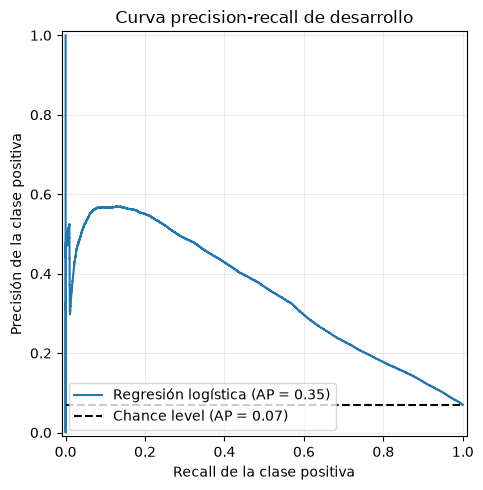

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

predicciones_lr = pd.read_csv(
    RESULTS_DIR / "probabilidades_validacion_lr.csv"
)

fig, ax = plt.subplots(figsize=(8, 5))

PrecisionRecallDisplay.from_predictions(
    predicciones_lr["y_true"],
    predicciones_lr["probabilidad"],
    name="Regresión logística",
    plot_chance_level=True,
    ax=ax,
)

ax.set(
    xlabel="Recall de la clase positiva",
    ylabel="Precisión de la clase positiva",
    title="Curva precision-recall de desarrollo",
)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "curva_precision_recall_lr.png", dpi=200)
plt.show()


### Selección del umbral de regresión logística

Se exploran 100 umbrales mediante CV con el pipeline ganador fijo, sin usar `X_test`. Se guarda `TunedThresholdClassifierCV`, cuyo `predict()` incorpora el umbral seleccionado (0.5487 en la ejecución guardada). Esto modifica las etiquetas, no el ranking de probabilidades por sí mismo [12]. Después se calculan 100 scores con ese umbral fijo; son diagnósticos de desarrollo y **no se mezclan con los scores a 0.5 de la comparación estadística**. El ajuste del umbral requiere 100 entrenamientos y un refit; la evaluación posterior añade otros 100.

In [21]:
from sklearn.model_selection import TunedThresholdClassifierCV, FixedThresholdClassifier, cross_validate

model_lr = TunedThresholdClassifierCV(
    search_lr.best_estimator_, scoring=scoring["f1"],
    response_method="predict_proba", thresholds=100, cv=cv,
    n_jobs=-1, store_cv_results=True,
)
model_lr.fit(X_train, y_train)
pd.DataFrame(model_lr.cv_results_).to_csv(RESULTS_DIR / "umbrales.csv", index=False)
joblib.dump(model_lr, RESULTS_DIR / "modelo_lr.joblib", compress=3)
(RESULTS_DIR / "umbral.json").write_text(
    json.dumps({"umbral": float(model_lr.best_threshold_), "f1_desarrollo": float(model_lr.best_score_)}, indent=2),
    encoding="utf-8",
)

scores_threshold = cross_validate(
    FixedThresholdClassifier(
        model_lr.estimator_, threshold=model_lr.best_threshold_,
        response_method="predict_proba",
    ),
    X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1, error_score="raise",
)
fold_scores_threshold = pd.DataFrame({m: scores_threshold[f"test_{m}"] for m in scoring})
fold_scores_threshold.to_csv(RESULTS_DIR / "scores_umbral_por_fold.csv", index_label="split")
summary_threshold = fold_scores_threshold.agg(["mean", "std"]).T
summary_threshold.columns = ["validacion_media", "validacion_std"]

final_pipeline = model_lr.estimator_
final_sampler = final_pipeline.named_steps["sampler"]
final_params = {
    "C": final_pipeline.named_steps["model"].C,
    "variables_seleccionadas": int(final_pipeline.named_steps["selector"].get_support().sum()),
    "positivos_por_negativo": "sin submuestreo" if final_sampler == "passthrough" else final_sampler.sampling_strategy,
    "transformacion": "log1p excepto age",
}
print(
    f"Umbral elegido: {model_lr.best_threshold_:.4f}\n\n"
    "Métricas de desarrollo por CV con ese umbral (clase positiva):\n"
    f"{summary_threshold.round(4).to_string()}\n\n"
    "Parámetros finales para model_lr.predict(X_nuevo):\n"
    + json.dumps(final_params, indent=2, ensure_ascii=False)
)


Umbral elegido: 0.5487

Métricas de desarrollo por CV con ese umbral (clase positiva):
           validacion_media  validacion_std
roc_auc              0.8426          0.0078
accuracy             0.9090          0.0030
precision            0.3791          0.0141
recall               0.4837          0.0197
f1                   0.4249          0.0140

Parámetros finales para model_lr.predict(X_nuevo):
{
  "C": 0.01,
  "variables_seleccionadas": 5,
  "positivos_por_negativo": 0.5,
  "transformacion": "log1p excepto age"
}


### Cálculo de la curva de aprendizaje

Se mantienen fijos los hiperparámetros y el umbral elegido de LR, y se repite el ajuste con cinco tamaños de entrenamiento dentro de cada fold. Con 100 particiones son **500 ajustes**; el eje horizontal cuenta las filas disponibles antes del submuestreo. La curva diagnostica la relación entre datos y desempeño, sin usar el test final [13].

In [23]:
from sklearn.model_selection import learning_curve, FixedThresholdClassifier

learning_model = FixedThresholdClassifier(
    search_lr.best_estimator_, threshold=model_lr.best_threshold_,
    response_method="predict_proba",
)
curve = learning_curve(
    learning_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring["f1"],
    train_sizes=[0.10, 0.25, 0.50, 0.75, 1.0],
    shuffle=True,
    random_state=SEED,
    n_jobs=-1,
    error_score="raise",
    return_times=False,
)

learning_sizes = curve[0]
learning_train = curve[1]
learning_validation = curve[2]


### Gráfica de aprendizaje

Se guardan los scores por tamaño y fold, y se trazan sus medias de F1. La diferencia entre entrenamiento y validación ayuda a describir generalización; esta curva no cambia los hiperparámetros ni constituye una nueva búsqueda.

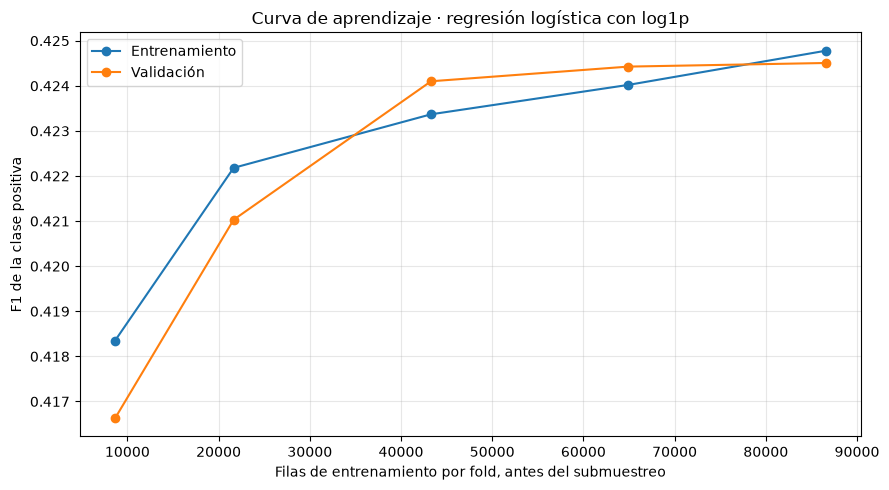

In [24]:
import matplotlib.pyplot as plt

pd.DataFrame(learning_train, index=learning_sizes).to_csv(
    RESULTS_DIR / "aprendizaje_train.csv", index_label="n_training_rows"
)
pd.DataFrame(learning_validation, index=learning_sizes).to_csv(
    RESULTS_DIR / "aprendizaje_validation.csv", index_label="n_training_rows"
)
plt.figure(figsize=(9, 5))
plt.plot(learning_sizes, learning_train.mean(axis=1), "o-", label="Entrenamiento")
plt.plot(learning_sizes, learning_validation.mean(axis=1), "o-", label="Validación")
plt.xlabel("Filas de entrenamiento por fold, antes del submuestreo")
plt.ylabel("F1 de la clase positiva")
plt.title("Curva de aprendizaje · regresión logística con log1p")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "curva_aprendizaje.png", dpi=150)
plt.show()


### Evaluación final de regresión logística

Se evalúa el modelo guardado con umbral optimizado sobre `X_test`, sin reentrenamiento. ROC-AUC usa probabilidades y las otras cuatro métricas usan las etiquetas de `predict()`. Los resultados del test se reservan para el informe final, no para reajustar decisiones [12], [4].

In [25]:
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
)

y_pred = model_lr.predict(X_test)

positive_column = list(model_lr.classes_).index(1)
y_proba = model_lr.predict_proba(X_test)[:, positive_column]

scores_test = pd.Series({
    "roc_auc": roc_auc_score(y_test, y_proba),
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, pos_label=1, zero_division=0),
    "recall": recall_score(y_test, y_pred, pos_label=1, zero_division=0),
    "f1": f1_score(y_test, y_pred, pos_label=1, zero_division=0),
}, name="test_final")

scores_test.to_csv(RESULTS_DIR / "scores_test.csv")
print(scores_test.round(4).to_string())


roc_auc      0.8369
accuracy     0.9050
precision    0.3625
recall       0.4835
f1           0.4144


## Segunda técnica: XGBoost

Elegí XGBoost como representante consolidado del boosting de árboles para datos tabulares. Complementa la regresión logística al capturar umbrales, no linealidades e interacciones entre ingresos, deuda e historial de morosidad. El modelo suma aportes de árboles sucesivos, con regularización para controlar su complejidad [14]. La elección de estos dos métodos clásicos permite comparar enfoques distintos sin afirmar que alguno será superior antes de evaluarlo.

Se utiliza `objective="binary:logistic"` para obtener probabilidades de clase 1. Se mantiene la escala original: los árboles dividen por umbrales y no requieren estandarización; una transformación estrictamente creciente conserva el orden de los valores, aunque la implementación aproximada y la precisión numérica pueden introducir diferencias. No se considera que el logaritmo sea obligatorio por la asimetría. `tree_method="hist"` limita los candidatos mediante histogramas [15].

El filtro es `mutual_info_classif`: puede captar dependencias no lineales. Se indican como continuos los tres ratios/importes, y como discretos edad en años y los conteos, conforme a su representación en el archivo [16]. En la búsqueda final `k="all"`: el filtro se ejecuta, pero **no elimina columnas**. Mantener las diez variables fue el resultado de la exploración previa, no una reducción efectiva de dimensionalidad.

### Pipeline de XGBoost

Se crea el filtro de información mutua y el clasificador. El peso positivo modifica el objetivo de entrenamiento y no genera personas sintéticas. Los valores iniciales del constructor que también aparecen en el grid son sustituidos por cada candidato de la búsqueda.

In [26]:
from functools import partial
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

continuous_features = ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]
mi_score = partial(
    mutual_info_classif,
    discrete_features=~X_train.columns.isin(continuous_features),
    random_state=SEED,
)
pipeline_xgb = Pipeline([
    ("selector", SelectKBest(mi_score)),
    ("model", XGBClassifier(
        objective="binary:logistic", eval_metric="logloss",
        learning_rate=0.05, n_estimators=300,
        min_child_weight=1, gamma=0, tree_method="hist",
        random_state=SEED, n_jobs=1,
    )),
])


### Espacio de búsqueda de XGBoost

La búsqueda final cruza **learning_rate = [0.01, 0.03, 0.05]** con **max_depth = [2, 4, 8]**: son **9 combinaciones y 900 ajustes de CV**, más refit. El learning rate controla la contribución de cada árbol y la profundidad limita su complejidad [15].

Se fijan `n_estimators=500`, `min_child_weight=1`, `reg_lambda=10`, `scale_pos_weight=3` y `k="all"`. El primero controla el número de árboles; `min_child_weight` limita la suma mínima de Hessianos del nodo; lambda penaliza los pesos de hojas; el peso positivo incrementa la contribución de esa clase. Estos valores no se optimizan en el grid final. Las elecciones proceden de la exploración previa y del presupuesto computacional; la documentación explica su función, no prescribe estos números.

Se habían considerado árboles más profundos, pero el costo aumentó sin una mejora apreciable en las métricas observadas. El criterio final sigue siendo F1 positivo a umbral 0.5, con los mismos 100 splits de LR. `eval_metric="logloss"` no sustituye ese criterio ni activa early stopping: aquí se construye el número fijo de árboles.

In [27]:
param_grid_xgb = {
    "selector__k": ["all"],
    "model__learning_rate": [0.01, 0.03, 0.05],
    "model__max_depth": [2, 4, 8],
    "model__n_estimators": [500],
    "model__min_child_weight": [1],
    "model__reg_lambda": [10],
    "model__scale_pos_weight": [3],
}
search_xgb = GridSearchCV(
    pipeline_xgb, param_grid_xgb, scoring=scoring, refit="f1", cv=cv,
    return_train_score=True, n_jobs=-1, error_score="raise",
)

search_xgb.fit(X_train, y_train);


### Resultados y archivos de XGBoost

Se guardan la búsqueda, el pipeline ganador, los hiperparámetros, el orden del entrenamiento y los scores por fold. Se muestran las cinco métricas de validación de la ganadora. El modelo guardado utiliza el umbral predeterminado 0.5.

In [32]:
import json
import joblib

RESULTS_XGB = ROOT / "results" / "xgboost"
RESULTS_XGB.mkdir(parents=True, exist_ok=True)
results_xgb = pd.DataFrame(search_xgb.cv_results_)
results_xgb.to_csv(RESULTS_XGB / "gridsearch.csv", index=False)
joblib.dump(search_xgb, RESULTS_XGB / "gridsearch.joblib", compress=3)
model_xgb = search_xgb.best_estimator_
joblib.dump(model_xgb, RESULTS_XGB / "modelo_xgb.joblib", compress=3)
X_train.index.to_series().to_csv(RESULTS_XGB / "orden_train.csv", index=False)

params_xgb = {name.split("__")[-1]: value for name, value in search_xgb.best_params_.items()}
(RESULTS_XGB / "hiperparametros.json").write_text(
    json.dumps(params_xgb, indent=2), encoding="utf-8"
)
best_xgb = results_xgb.iloc[search_xgb.best_index_]
summary_xgb = pd.DataFrame({
    "validacion_media": [best_xgb[f"mean_test_{m}"] for m in scoring],
    "validacion_std": [best_xgb[f"std_test_{m}"] for m in scoring],
}, index=list(scoring))
summary_xgb.to_csv(RESULTS_XGB / "resumen_validacion.csv")

print(
    "Hiperparámetros seleccionados:\n" + json.dumps(params_xgb, indent=2)
    + "\n\nValidación del GridSearch (umbral 0.5; precision, recall y F1 positivos):\n"
    + summary_xgb.round(4).to_string()
)


Hiperparámetros seleccionados:
{
  "learning_rate": 0.03,
  "max_depth": 4,
  "min_child_weight": 1,
  "n_estimators": 500,
  "reg_lambda": 10,
  "scale_pos_weight": 3,
  "k": "all"
}

Validación del GridSearch (umbral 0.5; precision, recall y F1 positivos):
           validacion_media  validacion_std
roc_auc              0.8574          0.0073
accuracy             0.9206          0.0022
precision            0.4300          0.0147
recall               0.4387          0.0177
f1                   0.4342          0.0146


### Probabilidades de validación de XGBoost

Se realizan 100 ajustes con la configuración ganadora para guardar las probabilidades sobre los mismos splits usados por LR. Los CSV permiten auditar los pares `(split, id)` y construir curvas sin repetir el GridSearch. Estas predicciones siguen siendo de desarrollo.

In [29]:
from sklearn.base import clone

RESULTS_XGB = ROOT / "results" / "xgboost"
RESULTS_XGB.mkdir(parents=True, exist_ok=True)

predicciones_xgb = []

for split, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train)):
    modelo_fold = clone(search_xgb.best_estimator_)
    modelo_fold.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

    probabilidades = modelo_fold.predict_proba(X_train.iloc[val_idx])[:, 1]

    predicciones_xgb.append(pd.DataFrame({
        "split": split,
        "id": X_train.index[val_idx],
        "y_true": y_train.iloc[val_idx].to_numpy(),
        "probabilidad": probabilidades,
    }))

predicciones_xgb = pd.concat(predicciones_xgb, ignore_index=True)
predicciones_xgb.to_csv(
    RESULTS_XGB / "probabilidades_validacion_xgb.csv", index=False
)


### Curva precision-recall de XGBoost

Se lee el CSV de probabilidades y se dibuja la curva con AP sobre las predicciones agrupadas. No se modifica el modelo ni se calcula AP como promedio entre folds. Para la versión final de XGBoost se conserva el umbral 0.5: la exploración de umbral no mostró una mejora relevante para el objetivo del proyecto.

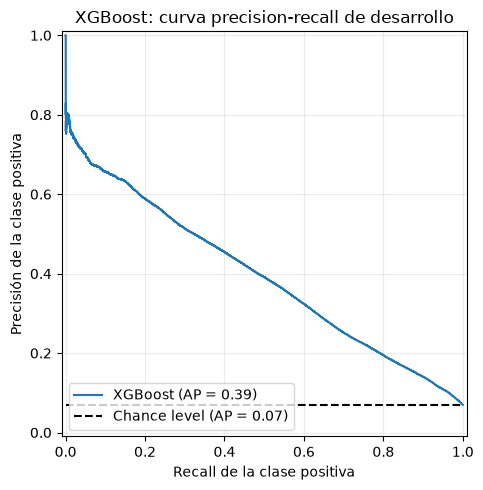

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay

predicciones_xgb = pd.read_csv(
    RESULTS_XGB / "probabilidades_validacion_xgb.csv"
)

fig, ax = plt.subplots(figsize=(8, 5))

PrecisionRecallDisplay.from_predictions(
    predicciones_xgb["y_true"],
    predicciones_xgb["probabilidad"],
    name="XGBoost",
    plot_chance_level=True,
    ax=ax,
)

ax.set(
    xlabel="Recall de la clase positiva",
    ylabel="Precisión de la clase positiva",
    title="XGBoost: curva precision-recall de desarrollo",
)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS_XGB / "curva_precision_recall_xgb.png", dpi=200)
plt.show()


### Cálculo de la curva de aprendizaje de XGBoost

Se fija la configuración ganadora y se usan cinco tamaños, con 5 folds × 2 repeticiones: **50 ajustes**. Se redujo el costo de este diagnóstico respecto a LR; por tanto, sus bandas o curvas no son una comparación estadística pareada entre técnicas. La comparación formal utiliza los 100 splits comunes de los GridSearch [13].

In [35]:
import numpy as np
from sklearn.model_selection import learning_curve, RepeatedStratifiedKFold

cv_learning_xgb = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=2, random_state=SEED,
)
sizes_xgb, train_f1_xgb, validation_f1_xgb, *_ = learning_curve(
    search_xgb.best_estimator_,
    X_train,
    y_train,
    train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
    cv=cv_learning_xgb,
    scoring=scoring["f1"],
    shuffle=True,
    random_state=SEED,
    n_jobs=-1,
    pre_dispatch="n_jobs",
    error_score="raise",
    return_times=True,
)

learning_folds_xgb = pd.DataFrame({
    "n_train": np.repeat(sizes_xgb, train_f1_xgb.shape[1]),
    "split": np.tile(np.arange(train_f1_xgb.shape[1]), len(sizes_xgb)),
    "f1_train": train_f1_xgb.ravel(),
    "f1_validacion": validation_f1_xgb.ravel(),
})
learning_folds_xgb.to_csv(RESULTS_XGB / "curva_aprendizaje_folds.csv", index=False)


### Gráfica de aprendizaje de XGBoost

Se resume el F1 por tamaño y se dibujan entrenamiento y validación con bandas de ± una desviación estándar entre particiones. Estas bandas muestran dispersión, **no intervalos de confianza**. Se guardan el resumen y la figura.

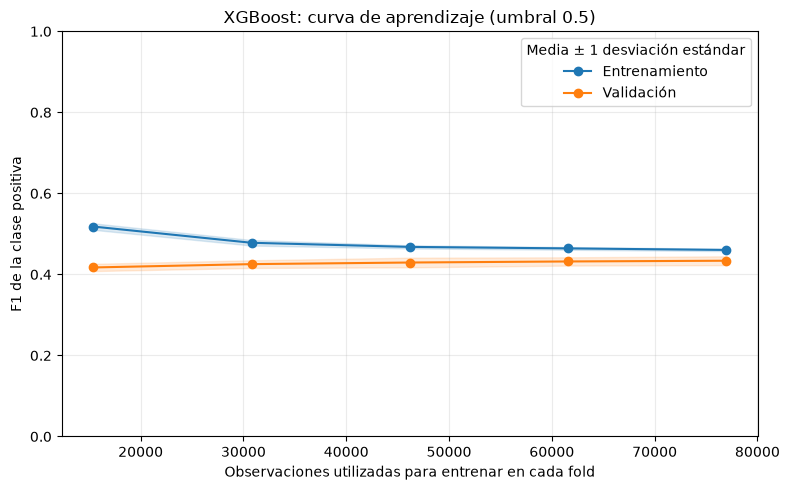

In [36]:
import matplotlib.pyplot as plt

learning_folds_xgb = pd.read_csv(RESULTS_XGB / "curva_aprendizaje_folds.csv")
learning_summary_xgb = learning_folds_xgb.groupby("n_train")[[
    "f1_train", "f1_validacion"
]].agg(["mean", "std"])
learning_summary_xgb.to_csv(RESULTS_XGB / "curva_aprendizaje_resumen.csv")

fig, ax = plt.subplots(figsize=(8, 5))
for metric, label in [("f1_train", "Entrenamiento"), ("f1_validacion", "Validación")]:
    mean = learning_summary_xgb[metric]["mean"]
    std = learning_summary_xgb[metric]["std"]
    line, = ax.plot(mean.index, mean, "o-", label=label)
    ax.fill_between(mean.index, mean - std, mean + std, color=line.get_color(), alpha=0.15)

ax.set(
    xlabel="Observaciones utilizadas para entrenar en cada fold",
    ylabel="F1 de la clase positiva", ylim=(0, 1),
    title="XGBoost: curva de aprendizaje (umbral 0.5)",
)
ax.grid(alpha=0.25)
ax.legend(title="Media ± 1 desviación estándar")

fig.tight_layout()
fig.savefig(RESULTS_XGB / "curva_aprendizaje.png", dpi=200, bbox_inches="tight")
plt.show()


### Evaluación final de XGBoost

Se aplica el pipeline ganador a `X_test` mediante `predict()` con umbral 0.5 y `predict_proba()`. Se guardan las cinco métricas y las predicciones individuales. Esta evaluación describe el modelo final; no se reutiliza para seleccionar hiperparámetros.

In [38]:
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
)

model_xgb = search_xgb.best_estimator_

y_pred_xgb = model_xgb.predict(X_test)
y_prob_xgb = model_xgb.predict_proba(X_test)[:, 1]

scores_test_xgb = pd.Series({
    "roc_auc": roc_auc_score(y_test, y_prob_xgb),
    "accuracy": accuracy_score(y_test, y_pred_xgb),
    "precision": precision_score(y_test, y_pred_xgb, pos_label=1, zero_division=0),
    "recall": recall_score(y_test, y_pred_xgb, pos_label=1, zero_division=0),
    "f1": f1_score(y_test, y_pred_xgb, pos_label=1, zero_division=0),
}, name="test_final")

scores_test_xgb.to_csv(RESULTS_XGB / "scores_test.csv")

pd.DataFrame({
    "y_true": y_test.to_numpy(),
    "prediccion": y_pred_xgb,
    "probabilidad": y_prob_xgb,
}, index=X_test.index).to_csv(
    RESULTS_XGB / "predicciones_test.csv", index_label="id"
)

print(scores_test_xgb.round(4).to_string())


roc_auc      0.8505
accuracy     0.9198
precision    0.4241
recall       0.4333
f1           0.4287


## Comparación estadística de las cinco métricas

La rúbrica solicita validación cruzada repetida. Se comparan las configuraciones ganadoras a **umbral 0.5**, utilizando los 100 scores de validación de cada GridSearch; no los scores de entrenamiento, ni las métricas de LR a umbral optimizado, ni el test final. Para ROC-AUC se usan scores continuos, independientes del umbral de decisión.

Los 96 215 ejemplos de desarrollo se reparten en 10 folds estratificados y se repite el reparto 10 veces. Cada ajuste utiliza aproximadamente 86 593–86 594 filas para entrenar y 9 621–9 622 para validar. Cada persona participa una vez en validación por repetición. Con los mismos datos, orden y semilla, ambos modelos comparten las particiones [2].

Para cada métrica construimos $d_i=score_{XGB,i}-score_{LR,i}$, con **n = 100 diferencias pareadas**. Son pares porque se evalúan sobre las mismas personas; no son 100 diferencias independientes, dado el solapamiento de los entrenamientos. Se emplea el t-test corregido de Nadeau–Bengio, siguiendo la implementación de referencia para CV repetida [17], [18]:

$$H_0:\mu_d=0,\qquad H_1:\mu_d\ne0,$$
$$SE_c=\sqrt{\left(\frac{1}{n}+\frac{n_{val}}{n_{train}}\right)s_d^2},\qquad t_c=\frac{\bar d}{SE_c}.$$

La razón de tamaños es aproximadamente 1/9 y se calcula antes del submuestreo interno. Con 99 grados de libertad, el p-value bilateral es $2P(T_{99}\ge |t_c|)$. La referencia t y la corrección son aproximadas; las particiones dependientes no se vuelven independientes.

Para controlar las cinco pruebas se aplica Bonferroni: $p_{ajustado}=\min(1,5p)$ y se rechaza H0 si $p_{ajustado}<0.05$. Los IC individuales del 99% se construyen como $\bar d\pm t_{0.995,99}SE_c$; su cobertura familiar nominal es al menos 95% bajo los supuestos del método [19]. El error estándar no es el margen del intervalo: este último es $2.6264\,SE_c$. No rechazar H0 no demuestra equivalencia, y significación no implica una mejora importante en la práctica.

**Limitación de selección:** los hiperparámetros se eligieron con estas mismas validaciones. Corregir la dependencia no elimina ese sesgo; por ello se presenta una comparación aproximada de desarrollo y se informa el test final por separado. Una evaluación externa a toda la selección, por ejemplo mediante CV anidada, ofrecería mayor rigor a un costo computacional superior [20].

### Preparación de los pares

Se comprueba que coincidan el orden del entrenamiento y las etiquetas e identificadores por split. Se extrae la primera fila de mejor rango F1 de cada GridSearch, como en su selección original, y se calculan las 100 diferencias de cada métrica. Se conservan también los scores pareados para reproducir el análisis.

In [39]:
import numpy as np
import pandas as pd

dir_lr = ROOT / "results" / "regresion_logistica" / "log_f1"
dir_xgb = ROOT / "results" / "xgboost"
RESULTS_COMPARISON = ROOT / "results" / "comparacion_estadistica"
metricas = ["roc_auc", "accuracy", "precision", "recall", "f1"]

orden_lr = pd.read_csv(dir_lr / "orden_train.csv")
orden_xgb = pd.read_csv(dir_xgb / "orden_train.csv")
assert orden_lr.equals(orden_xgb), "No coincide el orden de entrenamiento."

pares = []
scores_modelos = []
for carpeta, nombre in [(dir_lr, "lr"), (dir_xgb, "xgb")]:
    pares.append(pd.read_csv(
        carpeta / f"probabilidades_validacion_{nombre}.csv",
        usecols=["split", "id", "y_true"],
    ).sort_values(["split", "id"]).reset_index(drop=True))
    resultados = pd.read_csv(carpeta / "gridsearch.csv")

    mejor = resultados.loc[resultados["rank_test_f1"].idxmin()]
    scores_modelos.append(pd.DataFrame({
        m: [mejor[f"split{i}_test_{m}"] for i in range(100)] for m in metricas
    }))

assert pares[0].equals(pares[1]), "No coinciden las filas o etiquetas por fold."
assert pares[0]["split"].nunique() == 100
assert not pares[0].duplicated(["split", "id"]).any()
scores_lr, scores_xgb = scores_modelos
diferencias = scores_xgb - scores_lr
assert np.isfinite(diferencias.to_numpy()).all(), "Hay scores no válidos."

n_validacion = pares[0].groupby("split").size()
ratio_validacion_train = (n_validacion / (len(orden_lr) - n_validacion)).mean()
RESULTS_COMPARISON.mkdir(parents=True, exist_ok=True)
pd.concat({"lr": scores_lr, "xgb": scores_xgb, "diferencia": diferencias}, axis=1).to_csv(
    RESULTS_COMPARISON / "scores_pareados.csv", index_label="split",
)


### Contrastes e intervalos

Se calcula la media de las diferencias, su error estándar corregido, el estadístico t bilateral, el p-value y su ajuste Bonferroni. Los resultados incluyen IC individuales del 99% y una decisión por métrica. Todos los valores se guardan con precisión completa; el redondeo solo se aplica al imprimir.

In [40]:
from scipy.stats import t

alpha = 0.05
n = len(diferencias)
numero_pruebas = len(metricas)
critico = t.ppf(1 - alpha / (2 * numero_pruebas), df=n - 1)
filas = []

for metrica in metricas:
    d = diferencias[metrica]
    media = d.mean()
    error = np.sqrt((1 / n + ratio_validacion_train) * d.var(ddof=1))
    if error == 0:
        raise ValueError(f"{metrica}: diferencias constantes; revisar el contraste.")
    estadistico = media / error
    p = 2 * t.sf(abs(estadistico), df=n - 1)
    filas.append({
        "metrica": metrica,
        "media_lr": scores_lr[metrica].mean(),
        "media_xgb": scores_xgb[metrica].mean(),
        "diferencia_xgb_lr": media,
        "error_corregido": error,
        "ic99_inferior": media - critico * error,
        "ic99_superior": media + critico * error,
        "t_corregido": estadistico,
        "p_bilateral": p,
        "p_bonferroni": min(1.0, p * numero_pruebas),
    })

comparacion = pd.DataFrame(filas).set_index("metrica")
comparacion["rechazar_H0"] = comparacion["p_bonferroni"] < alpha
comparacion.to_csv(RESULTS_COMPARISON / "contrastes_corregidos.csv")
print("Diferencia = XGBoost − LR; ambos a umbral 0.5.")
print("Decisión: p_bonferroni < 0.05. IC individuales 99%; cobertura familiar nominal ≥95%.")
print(comparacion.to_string(float_format=lambda x: f"{x:.5g}"))


Diferencia = XGBoost − LR; ambos a umbral 0.5.
Decisión: p_bonferroni < 0.05. IC individuales 99%; cobertura familiar nominal ≥95%.
           media_lr  media_xgb  diferencia_xgb_lr  error_corregido  ic99_inferior  ic99_superior  t_corregido  p_bilateral  p_bonferroni  rechazar_H0
metrica                                                                                                                                              
roc_auc     0.84259    0.85742           0.014829        0.0010587       0.012049        0.01761       14.007   3.1812e-25    1.5906e-24         True
accuracy    0.89888    0.92056           0.021685       0.00092433       0.019257       0.024112        23.46   3.1886e-42    1.5943e-41         True
precision   0.34971    0.42999           0.080281        0.0039556       0.069892        0.09067       20.296   4.6744e-37    2.3372e-36         True
recall       0.5285    0.43872          -0.089783        0.0044299       -0.10142      -0.078148      -20.268   5.2197

### Lectura de la comparación de desarrollo

Los resultados guardados rechazan H0 en las cinco métricas tras las dos correcciones. La dirección no es la misma para todas: XGBoost tiene mayor media de ROC-AUC, accuracy, precisión y F1, mientras que LR tiene mayor recall. Para F1, la diferencia XGBoost − LR es **0.013423**, con error estándar corregido **0.003489**, IC aproximado del 99% **[0.004261, 0.022586]** y p ajustado **0.001056**. La mejora es de 1.34 puntos porcentuales de F1; no significa superioridad en todas las métricas ni una garantía de utilidad práctica.

Estos valores describen las configuraciones a 0.5. A continuación se muestran los modelos finales de test con sus umbrales respectivos, que constituyen una comparación descriptiva distinta.

## Evaluación final conjunta y matrices de confusión

Se utilizan las mismas **24 054 personas del test**: 22 383 de clase 0 y 1 671 de clase 1. LR usa su umbral elegido de 0.5487 y XGBoost conserva 0.5. Se cargan los modelos persistidos y se calculan predicciones, sin volver a entrenar ni buscar umbrales. Se comprueba que las cinco métricas coincidan con los CSV de evaluación final.

Cada matriz presenta **cantidad y porcentaje dentro de la clase real**: cada fila suma 100%. Así, la celda real 1/predicho 1 muestra el recall positivo, y real 0/predicho 1 la tasa de falsos positivos. La precisión tiene otro denominador, los predichos como positivos; se informa por separado para no confundirla con un porcentaje por fila [6].

In [ ]:
from sklearn.metrics import confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
import joblib
import json

RESULTS_FINAL = ROOT / "results" / "evaluacion_final"
RESULTS_FINAL.mkdir(parents=True, exist_ok=True)
modelos_finales = {
    "Regresión logística": ("lr", ROOT / "results" / "regresion_logistica" / "log_f1"),
    "XGBoost": ("xgb", ROOT / "results" / "xgboost"),
}
matrices_test = {}
resumen_test = []
for nombre, (clave, carpeta) in modelos_finales.items():
    modelo = joblib.load(carpeta / f"modelo_{clave}.joblib")
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, list(modelo.classes_).index(1)]
    umbral = float(modelo.best_threshold_) if clave == "lr" else 0.5
    scores = pd.Series({
        "roc_auc": roc_auc_score(y_test, prob),
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })
    guardados = pd.read_csv(carpeta / "scores_test.csv", index_col=0).iloc[:, 0]
    assert np.allclose(scores, guardados.loc[scores.index]), "Las métricas no coinciden con el test guardado."
    pd.DataFrame({"y_true": y_test.to_numpy(), "prediccion": pred, "probabilidad": prob},
                 index=X_test.index).to_csv(RESULTS_FINAL / f"predicciones_test_{clave}.csv", index_label="id")
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    porcentaje = 100 * cm / cm.sum(axis=1, keepdims=True)
    matrices_test[nombre] = (cm, porcentaje, umbral)
    for tipo, valores in [("conteos", cm), ("porcentaje_fila", porcentaje)]:
        pd.DataFrame(valores, index=["real_0", "real_1"], columns=["pred_0", "pred_1"]).to_csv(
            RESULTS_FINAL / f"matriz_{clave}_{tipo}.csv")
    resumen_test.append({"modelo": nombre, "umbral": umbral, **scores.to_dict(),
                         "falsas_alarmas_entre_predichos_positivos_pct": 100 * (1 - scores["precision"])})

resumen_test = pd.DataFrame(resumen_test).set_index("modelo")
resumen_test.to_csv(RESULTS_FINAL / "resumen_test.csv")
display(resumen_test.round(4))

,umbral,roc_auc,accuracy,precision,recall,f1,falsas_alarmas_entre_predichos_positivos_pct
modelo,,,,,,,
Regresión logística,0.5487,0.8369,0.9050,0.3625,0.4835,0.4144,63.7506
XGBoost,0.5000,0.8505,0.9198,0.4241,0.4333,0.4287,57.5864


### Dos matrices con el mismo denominador y escala

Se grafican ambas matrices con escala de color de 0% a 100%, cantidades absolutas y porcentajes por fila. Las etiquetas separan la clase real de la predicha y hacen explícito el umbral aplicado. Se guardan PNG y PDF para reutilizar las figuras en el informe.

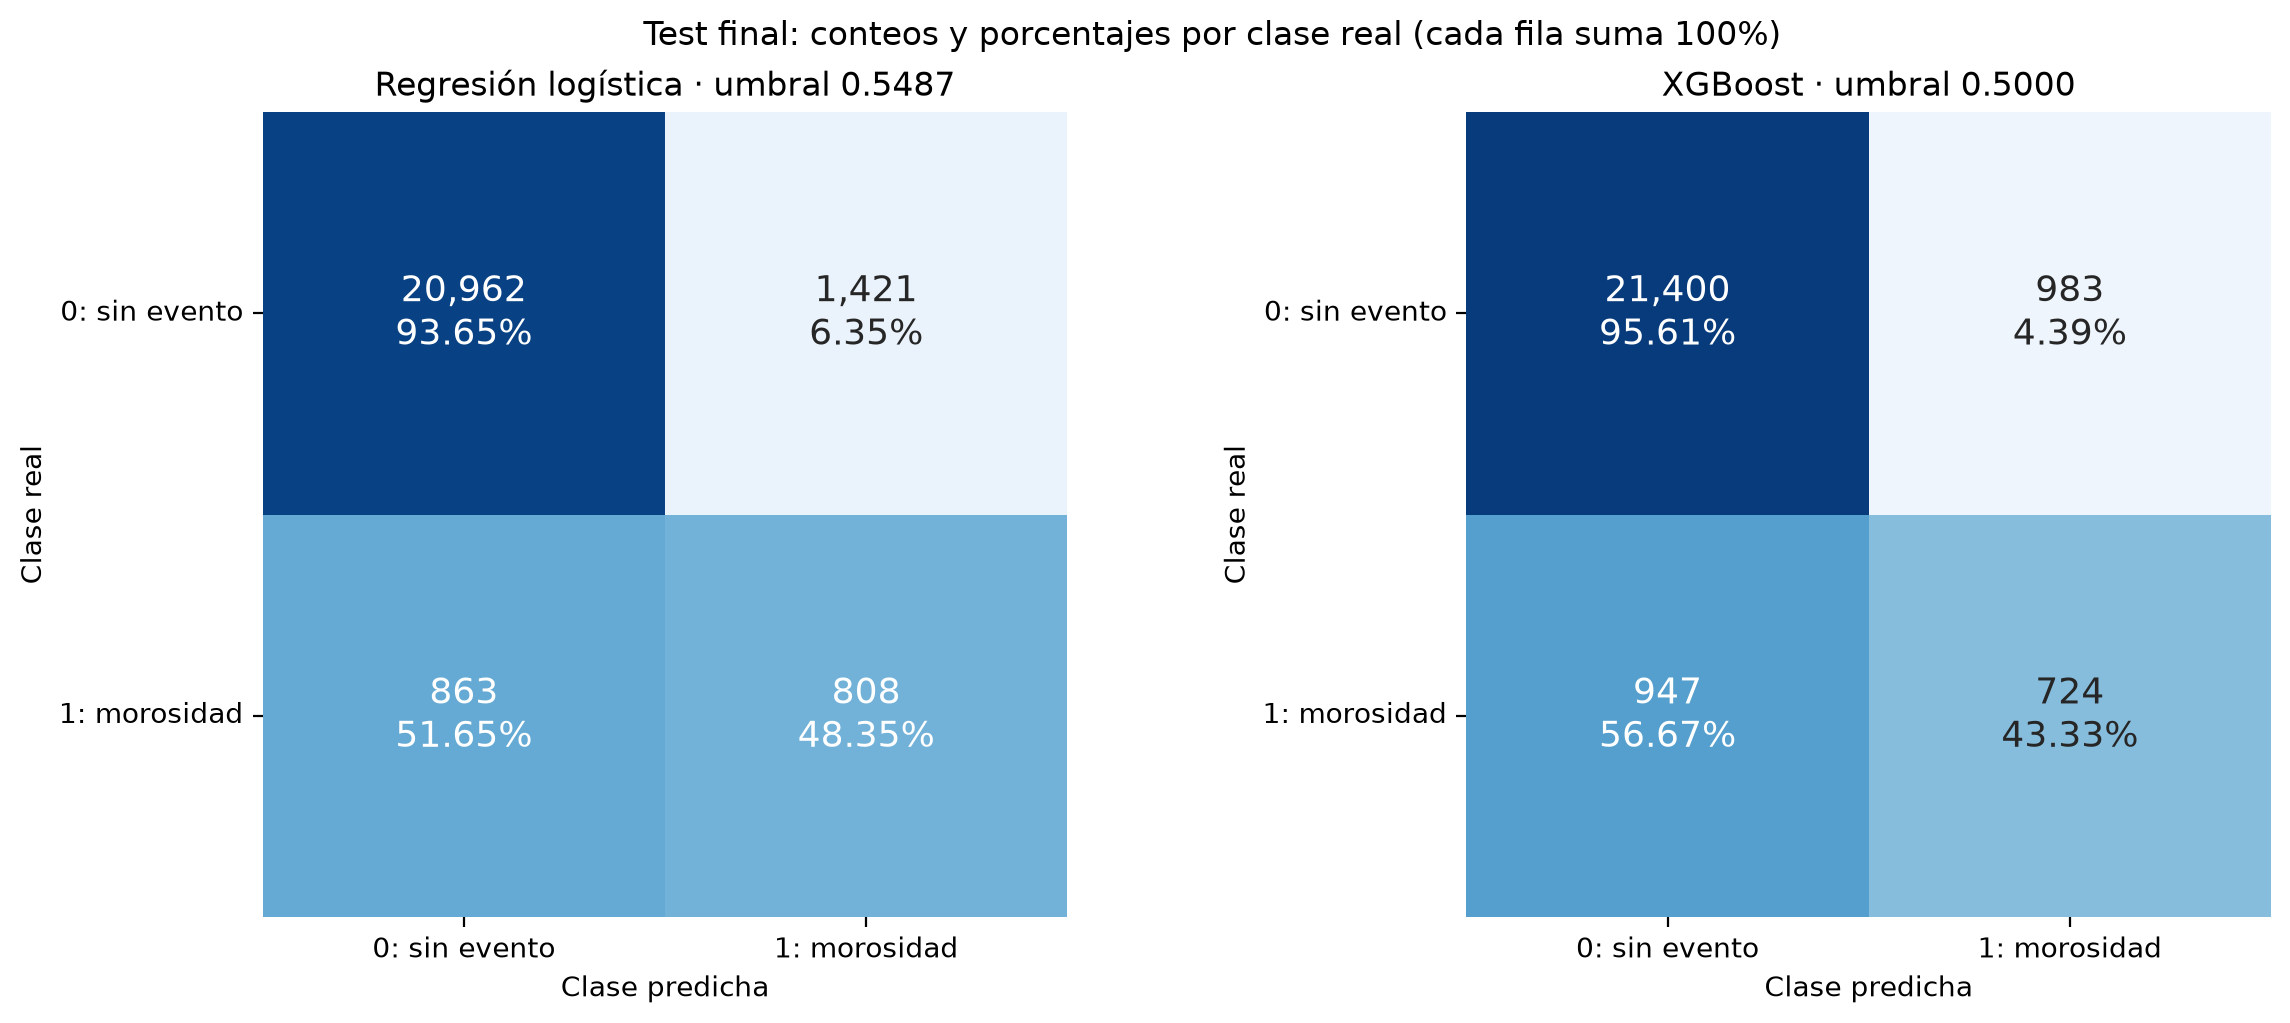

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, (nombre, (cm, porcentaje, umbral)) in zip(axes, matrices_test.items()):
    etiquetas = np.array([[f"{cm[i, j]:,}\n{porcentaje[i, j]:.2f}%" for j in range(2)] for i in range(2)])
    sns.heatmap(
        porcentaje, annot=etiquetas, fmt="", cmap="Blues", vmin=0, vmax=100,
        square=True, cbar=False, ax=ax,
        xticklabels=["0: sin evento", "1: morosidad"],
        yticklabels=["0: sin evento", "1: morosidad"],
        annot_kws={"fontsize": 13},
    )
    ax.set_title(f"{nombre} · umbral {umbral:.4f}")
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.tick_params(axis="y", rotation=0)
fig.suptitle("Test final: conteos y porcentajes por clase real (cada fila suma 100%)")
fig.savefig(RESULTS_FINAL / "matrices_confusion_test.png", dpi=200, bbox_inches="tight")
fig.savefig(RESULTS_FINAL / "matrices_confusion_test.pdf", bbox_inches="tight")
plt.show()

## Reflexión final: objetivo, resultados y límites

En el test, XGBoost alcanza F1 **0.4287**, precisión **0.4241** y recall **0.4333**; LR alcanza F1 **0.4144**, precisión **0.3625** y recall **0.4835**. XGBoost produce menos falsos positivos (983 frente a 1 421), pero también detecta menos positivos reales (724 frente a 808). Por tanto, el resultado no se resume en que un modelo sea mejor en todos los aspectos.

La elección de F1 resulta coherente con buscar un compromiso, pero **no cumplió por sí sola una exigencia de precisión alta**. Entre las predicciones positivas, aproximadamente 57.59% son falsas alarmas en XGBoost y 63.75% en LR. Estos porcentajes usan predicciones positivas como denominador, no la clase real negativa de las matrices. Si una aplicación exigiera un límite de falsas alarmas, habría que definir costos o restricciones operativas con datos de desarrollo; este proyecto no convierte sus resultados en una regla de aprobación crediticia.

ROC-AUC se mantiene como medida complementaria de discriminación, y las curvas PR y matrices permiten describir el punto de operación. El desbalance justifica prestar atención a la clase positiva, pero no invalida ROC-AUC ni demuestra que F1 sea siempre la mejor métrica [10].

Las principales limitaciones son la exclusión de registros sin ingresos, los valores extremos de significado no confirmado, el alcance finito de los grids y la selección repetida sobre el mismo conjunto de desarrollo. Los p-values y los intervalos de CV son aproximados y no corrigen esta última fuente de optimismo [3], [20]. El test se presenta separado, sin utilizar sus resultados para nuevos ajustes.

Para explicar las matrices con mis propias palabras: ¿cuántos casos de morosidad detecta cada modelo?, ¿cuántos pierde?, ¿cuántas falsas alarmas genera? La respuesta debe especificar el denominador y el umbral, además de la métrica resumida.

## Referencias

[1] Kaggle, “Give Me Some Credit,” competencia y archivos de datos, 2011. [En línea]. Disponible: [Kaggle](https://www.kaggle.com/c/GiveMeSomeCredit/data). [Accedido: 12-oct-2026]. Se utiliza también el archivo adjunto «Data Dictionary.xls».

[2] Scikit-learn developers, “Cross-validation: evaluating estimator performance,” *scikit-learn documentation*. [En línea]. Disponible: [documentación](https://scikit-learn.org/stable/modules/cross_validation.html). [Accedido: 12-oct-2026].

[3] J. A. C. Sterne et al., “Multiple imputation for missing data in epidemiological and clinical research: potential and pitfalls,” *BMJ*, vol. 338, art. b2393, 2009, doi: [10.1136/bmj.b2393](https://doi.org/10.1136/bmj.b2393).

[4] Scikit-learn developers, “Common pitfalls and recommended practices,” *scikit-learn documentation*. [En línea]. Disponible: [documentación](https://scikit-learn.org/stable/common_pitfalls.html). [Accedido: 12-oct-2026].

[5] Scikit-learn developers, “Feature selection,” *scikit-learn documentation*. [En línea]. Disponible: [documentación](https://scikit-learn.org/stable/modules/feature_selection.html). [Accedido: 12-oct-2026].

[6] Scikit-learn developers, “Metrics and scoring: quantifying the quality of predictions,” *scikit-learn documentation*. [En línea]. Disponible: [documentación](https://scikit-learn.org/stable/modules/model_evaluation.html). [Accedido: 12-oct-2026].

[7] Imbalanced-learn developers, “RandomUnderSampler,” *imbalanced-learn documentation*. [En línea]. Disponible: [documentación](https://imbalanced-learn.org/stable/references/generated/imblearn.under_sampling.RandomUnderSampler.html). [Accedido: 12-oct-2026].

[8] Scikit-learn developers, “LogisticRegression,” *scikit-learn documentation*. [En línea]. Disponible: [documentación](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). [Accedido: 12-oct-2026].

[9] Scikit-learn developers, “Preprocessing data,” *scikit-learn documentation*. [En línea]. Disponible: [documentación](https://scikit-learn.org/stable/modules/preprocessing.html). [Accedido: 12-oct-2026].

[10] T. Saito and M. Rehmsmeier, “The Precision-Recall Plot Is More Informative than the ROC Plot When Evaluating Binary Classifiers on Imbalanced Datasets,” *PLOS ONE*, vol. 10, no. 3, art. e0118432, 2015, doi: [10.1371/journal.pone.0118432](https://doi.org/10.1371/journal.pone.0118432).

[11] Scikit-learn developers, “GridSearchCV,” *scikit-learn documentation*. [En línea]. Disponible: [documentación](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html). [Accedido: 12-oct-2026].

[12] Scikit-learn developers, “Tuning the decision threshold for class prediction,” *scikit-learn documentation*. [En línea]. Disponible: [documentación](https://scikit-learn.org/stable/modules/classification_threshold.html). [Accedido: 12-oct-2026].

[13] Scikit-learn developers, “Validation curves: plotting scores to evaluate models,” *scikit-learn documentation*. [En línea]. Disponible: [documentación](https://scikit-learn.org/stable/modules/learning_curve.html). [Accedido: 12-oct-2026].

[14] T. Chen and C. Guestrin, “XGBoost: A Scalable Tree Boosting System,” in *Proc. 22nd ACM SIGKDD Int. Conf. Knowledge Discovery and Data Mining*, 2016, pp. 785–794, doi: [10.1145/2939672.2939785](https://doi.org/10.1145/2939672.2939785). Versión de los autores: [arXiv:1603.02754](https://arxiv.org/abs/1603.02754).

[15] XGBoost developers, “XGBoost Parameters,” *XGBoost documentation*. [En línea]. Disponible: [documentación](https://xgboost.readthedocs.io/en/stable/parameter.html). [Accedido: 12-oct-2026].

[16] Scikit-learn developers, “mutual_info_classif,” *scikit-learn documentation*. [En línea]. Disponible: [documentación](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.mutual_info_classif.html). [Accedido: 12-oct-2026].

[17] C. Nadeau and Y. Bengio, “Inference for the Generalization Error,” *Machine Learning*, vol. 52, no. 3, pp. 239–281, 2003, doi: [10.1023/A:1024068626366](https://doi.org/10.1023/A:1024068626366).

[18] Scikit-learn developers, “Statistical comparison of models using grid search,” *scikit-learn examples*. [En línea]. Disponible: [ejemplo](https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_stats.html). [Accedido: 12-oct-2026].

[19] NIST/SEMATECH, “Bonferroni’s method,” *e-Handbook of Statistical Methods*, sec. 7.4.7.3. [En línea]. Disponible: [NIST](https://www.itl.nist.gov/div898/handbook/prc/section4/prc473.htm). [Accedido: 12-oct-2026].

[20] G. C. Cawley and N. L. C. Talbot, “On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation,” *Journal of Machine Learning Research*, vol. 11, pp. 2079–2107, 2010. [En línea]. Disponible: [artículo](https://www.jmlr.org/papers/v11/cawley10a.html).